In [1]:
# Import required libraries for city comparison

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("bmh")

In [2]:
# Read the weather dataset

weather_df = pd.read_csv("../data/processed/pakistan_weather_2025.csv")

weather_df.head()

,date,city,temp_max,temp_min,precipitation
0,2025-01-01,Karachi,26.2,15.2,0.0
1,2025-01-02,Karachi,25.6,14.8,0.0
2,2025-01-03,Karachi,24.6,14.8,0.0
3,2025-01-04,Karachi,24.2,17.2,0.0
4,2025-01-05,Karachi,22.5,13.0,0.0


In [3]:
# Read the cost of living dataset

cost_df = pd.read_csv("../data/processed/pakistan_city_cost_of_living_cleaned.csv")

cost_df.head()

,Item,Unit,Islamabad,Lahore,Karachi,Peshawar,Quetta
0,Wheat Flour Bag,20 Kg,3286.54,2477.84,3412.18,3038.96,3164.99
1,Rice Basmati Broken (Average Quality),1 Kg,274.83,228.47,283.54,222.18,279.93
2,Rice IRRI-6/9 (Sindh/Punjab),1 Kg,178.64,NaN,175.45,134.35,169.88
3,Bread plain (Small Size),Each,120.00,130.00,140.00,120.00,130.00
4,Beef with Bone (Average Quality),1 Kg,1491.13,1295.92,1470.13,1274.41,1274.10


In [4]:
# Read the economic summary dataset

economic_df = pd.read_csv("../data/processed/pakistan_city_economic_summary.csv")

economic_df.head()

,District,Establishments,Workforce
0,Lahore,429891,2014908
1,Karachi (4 districts),341682,1567422
2,Peshawar,116022,587659
3,Quetta,84231,438882
4,Islamabad,86154,621514


In [5]:
# Check the columns of all three datasets

print("Weather Columns:")
print(weather_df.columns)

print("\nCost of Living Columns:")
print(cost_df.columns)

print("\nEconomic Columns:")
print(economic_df.columns)

Weather Columns:
Index(['date', 'city', 'temp_max', 'temp_min', 'precipitation'], dtype='str')

Cost of Living Columns:
Index(['Item', 'Unit', 'Islamabad', 'Lahore', 'Karachi', 'Peshawar', 'Quetta'], dtype='str')

Economic Columns:
Index(['District', 'Establishments', 'Workforce'], dtype='str')


In [6]:
# Calculate weather summary of each city

weather_summary = weather_df.groupby("city").agg(
    Average_max_temp=("temp_max", "mean"),
    Average_min_temp=("temp_min", "mean"),
    Total_precipitation=("precipitation", "sum")
).reset_index()

weather_summary.round(2)

,city,Average_max_temp,Average_min_temp,Total_precipitation
0,Islamabad,27.81,17.22,1188.2
1,Karachi,30.91,23.08,341.0
2,Lahore,30.11,18.97,931.9
3,Peshawar,29.11,16.17,665.3
4,Quetta,25.42,11.42,179.4


In [7]:
# Calculate the average price of selected items in each city

cities = ["Islamabad", "Lahore", "Karachi", "Peshawar", "Quetta"]

cost_summary = cost_df[cities].mean().reset_index()

cost_summary.columns = ["city", "Average_item_price"]

cost_summary.round(2)

,city,Average_item_price
0,Islamabad,817.34
1,Lahore,788.10
2,Karachi,783.87
3,Peshawar,772.05
4,Quetta,758.54


In [8]:
# Check all locations available in the economic summary dataset

economic_df["District"].unique()

<StringArray>
['Lahore', 'Karachi (4 districts)', 'Peshawar', 'Quetta', 'Islamabad']
Length: 5, dtype: str

In [9]:
# Display economic data for all locations

economic_df

,District,Establishments,Workforce
0,Lahore,429891,2014908
1,Karachi (4 districts),341682,1567422
2,Peshawar,116022,587659
3,Quetta,84231,438882
4,Islamabad,86154,621514


In [10]:
# Rename District column into city for comparison

economic_summary = economic_df.rename(
    columns={"District": "city"}
).copy()

# Standardize Karachi city name

economic_summary["city"] = economic_summary["city"].replace(
    "Karachi (4 districts)", "Karachi"
)

economic_summary

,city,Establishments,Workforce
0,Lahore,429891,2014908
1,Karachi,341682,1567422
2,Peshawar,116022,587659
3,Quetta,84231,438882
4,Islamabad,86154,621514


In [11]:
# Check whether all five cities are available

economic_summary["city"].unique()

<StringArray>
['Lahore', 'Karachi', 'Peshawar', 'Quetta', 'Islamabad']
Length: 5, dtype: str

In [12]:
# Combine weather and cost of living summaries

city_comparison = pd.merge(
    weather_summary,
    cost_summary,
    on="city"
)

city_comparison

,city,Average_max_temp,Average_min_temp,Total_precipitation,Average_item_price
0,Islamabad,27.814521,17.222466,1188.2,817.340784
1,Karachi,30.906575,23.075616,341.0,783.865686
2,Lahore,30.114795,18.966575,931.9,788.101800
3,Peshawar,29.114795,16.169315,665.3,772.053333
4,Quetta,25.415342,11.417260,179.4,758.544118


In [13]:
# Add economic indicators to the city comparison dataset

city_comparison = pd.merge(
    city_comparison,
    economic_summary,
    on="city"
)

city_comparison

,city,Average_max_temp,Average_min_temp,Total_precipitation,Average_item_price,Establishments,Workforce
0,Islamabad,27.814521,17.222466,1188.2,817.340784,86154,621514
1,Karachi,30.906575,23.075616,341.0,783.865686,341682,1567422
2,Lahore,30.114795,18.966575,931.9,788.101800,429891,2014908
3,Peshawar,29.114795,16.169315,665.3,772.053333,116022,587659
4,Quetta,25.415342,11.417260,179.4,758.544118,84231,438882


In [14]:
# Check the final city comparison dataset

city_comparison.info()

<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   city                 5 non-null      str    
 1   Average_max_temp     5 non-null      float64
 2   Average_min_temp     5 non-null      float64
 3   Total_precipitation  5 non-null      float64
 4   Average_item_price   5 non-null      float64
 5   Establishments       5 non-null      int64  
 6   Workforce            5 non-null      int64  
dtypes: float64(4), int64(2), str(1)
memory usage: 412.0 bytes


In [15]:
# Check missing values in the final dataset

city_comparison.isna().sum()

city                   0
Average_max_temp       0
Average_min_temp       0
Total_precipitation    0
Average_item_price     0
Establishments         0
Workforce              0
dtype: int64

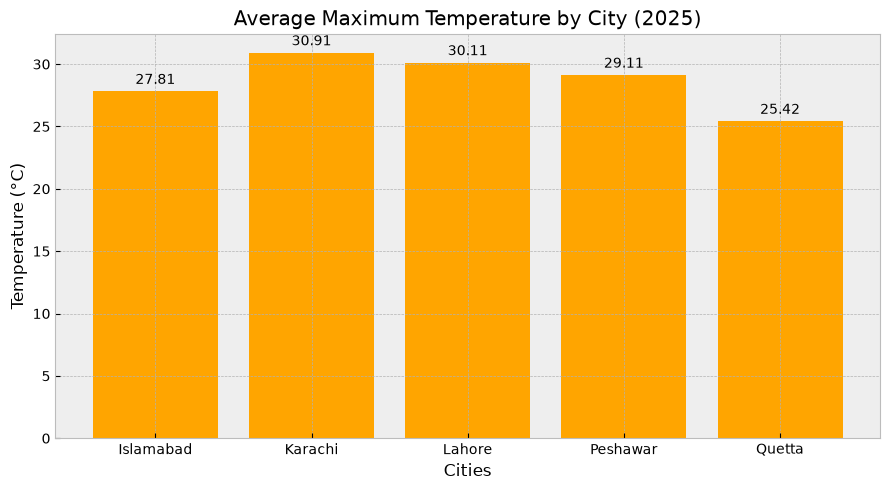

In [16]:
# Compare average maximum temperature of all five cities

plt.figure(figsize=(9, 5))

bars = plt.bar(
    city_comparison["city"],
    city_comparison["Average_max_temp"],
    color="orange"
)

plt.bar_label(bars, fmt="%.2f", padding=3)

plt.title("Average Maximum Temperature by City (2025)")
plt.xlabel("Cities")
plt.ylabel("Temperature (°C)")
plt.tight_layout()
plt.show()

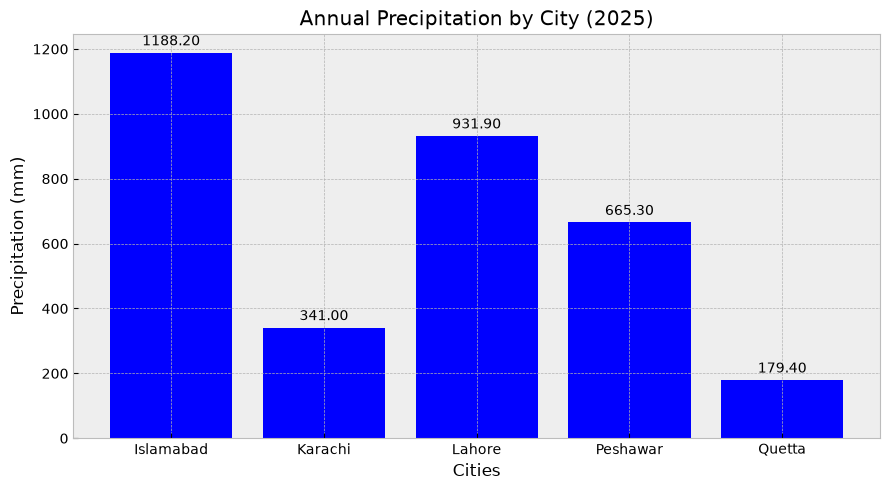

In [17]:
# Compare total annual precipitation of all five cities

plt.figure(figsize=(9, 5))

bars = plt.bar(
    city_comparison["city"],
    city_comparison["Total_precipitation"],
    color="blue"
)

plt.bar_label(bars, fmt="%.2f", padding=3)

plt.title("Annual Precipitation by City (2025)")
plt.xlabel("Cities")
plt.ylabel("Precipitation (mm)")
plt.tight_layout()
plt.show()

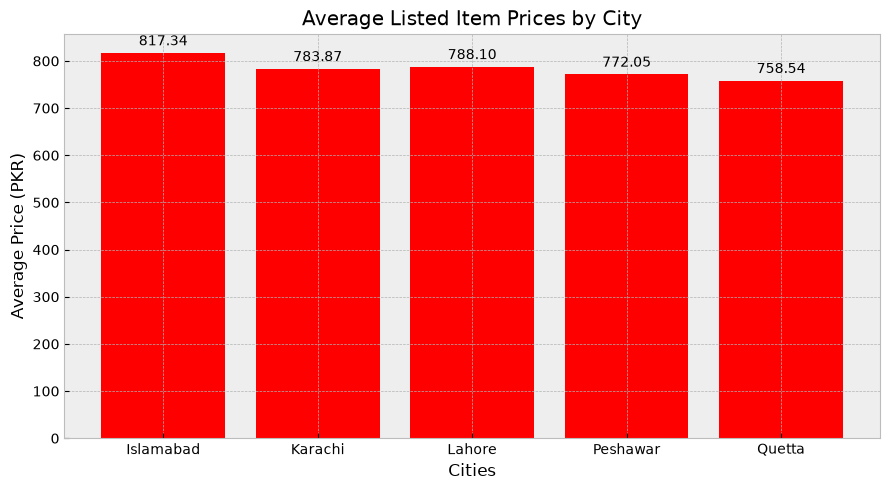

In [18]:
# Compare average prices of listed items across all five cities

plt.figure(figsize=(9, 5))

bars = plt.bar(
    city_comparison["city"],
    city_comparison["Average_item_price"],
    color="red"
)

plt.bar_label(bars, fmt="%.2f", padding=3)

plt.title("Average Listed Item Prices by City")
plt.xlabel("Cities")
plt.ylabel("Average Price (PKR)")
plt.tight_layout()
plt.show()

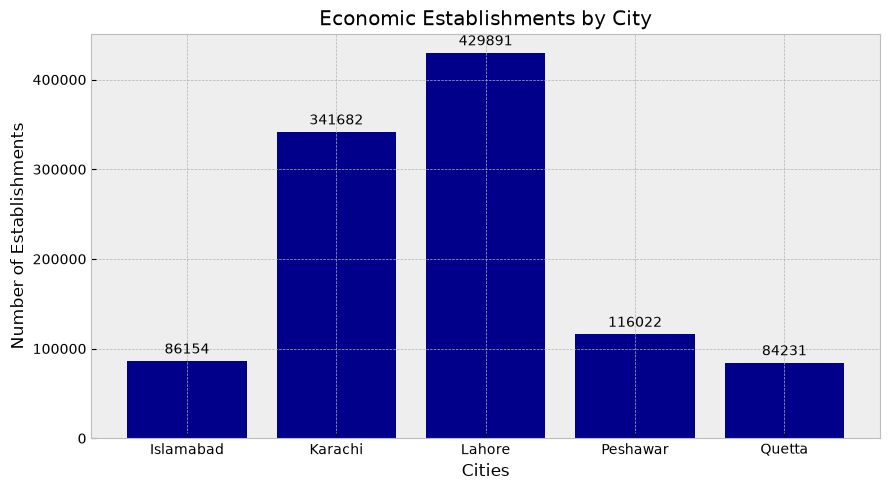

In [19]:
# Compare total economic establishments across all five cities

plt.figure(figsize=(9, 5))

bars = plt.bar(
    city_comparison["city"],
    city_comparison["Establishments"],
    color="darkblue"
)

plt.bar_label(bars, fmt="%.0f", padding=3)

plt.title("Economic Establishments by City")
plt.xlabel("Cities")
plt.ylabel("Number of Establishments")
plt.tight_layout()
plt.show()

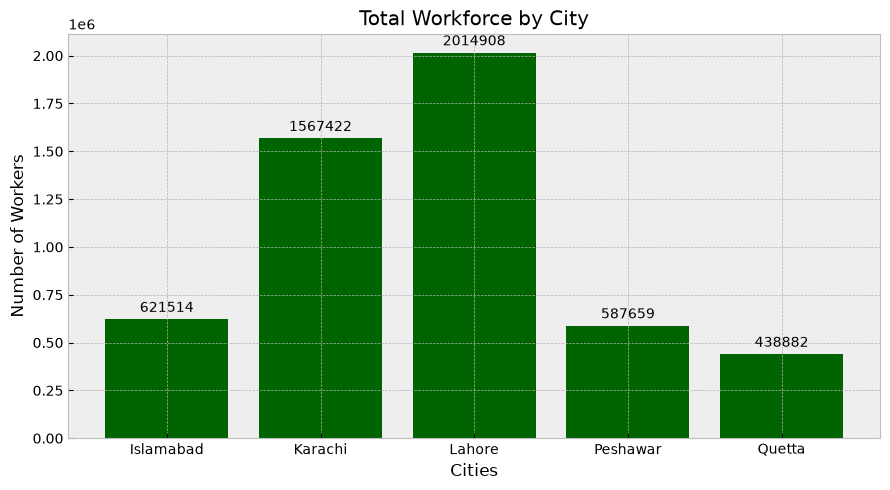

In [20]:
# Compare total workforce across all five cities

plt.figure(figsize=(9, 5))

bars = plt.bar(
    city_comparison["city"],
    city_comparison["Workforce"],
    color="darkgreen"
)

plt.bar_label(bars, fmt="%.0f", padding=3)

plt.title("Total Workforce by City")
plt.xlabel("Cities")
plt.ylabel("Number of Workers")
plt.tight_layout()
plt.show()

In [21]:
# Display the final comparison of all five cities

city_comparison.round(2)

,city,Average_max_temp,Average_min_temp,Total_precipitation,Average_item_price,Establishments,Workforce
0,Islamabad,27.81,17.22,1188.2,817.34,86154,621514
1,Karachi,30.91,23.08,341.0,783.87,341682,1567422
2,Lahore,30.11,18.97,931.9,788.10,429891,2014908
3,Peshawar,29.11,16.17,665.3,772.05,116022,587659
4,Quetta,25.42,11.42,179.4,758.54,84231,438882


In [22]:
# Calculate monthly average maximum temperature of each city

weather_df["date"] = pd.to_datetime(weather_df["date"])
weather_df["month"] = weather_df["date"].dt.month

monthly_comparison = weather_df.groupby(
    ["city", "month"]
).agg(
    Average_monthly_temp=("temp_max", "mean")
).reset_index()

monthly_comparison.head()

,city,month,Average_monthly_temp
0,Islamabad,1,18.651613
1,Islamabad,2,20.382143
2,Islamabad,3,23.519355
3,Islamabad,4,33.660000
4,Islamabad,5,35.467742


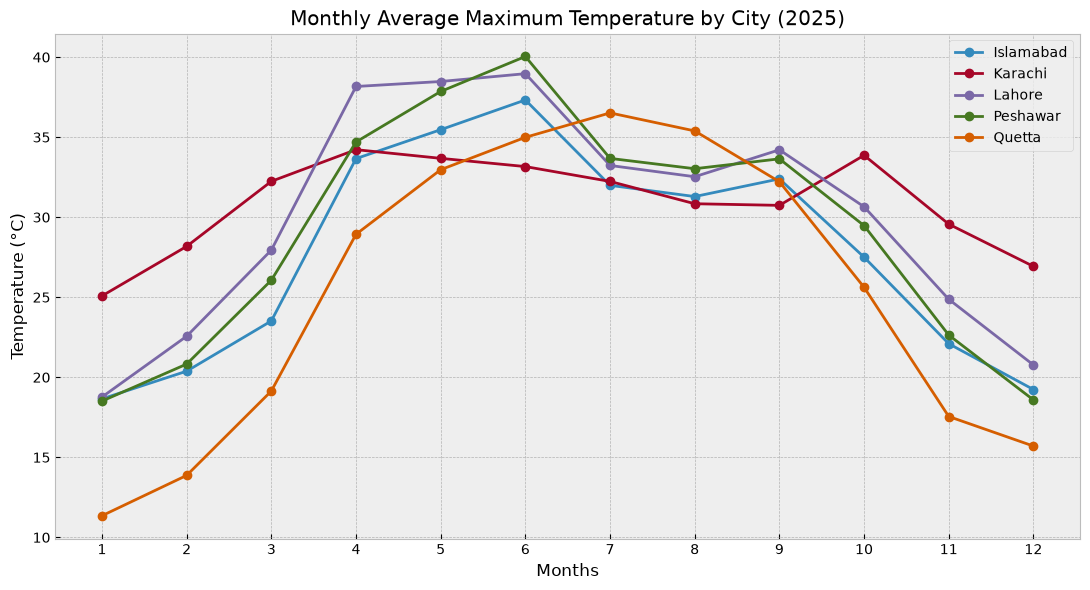

In [24]:
# Visualize monthly temperature trends of all five cities

plt.figure(figsize=(11, 6))

for city in monthly_comparison["city"].unique():
    city_data = monthly_comparison[
        monthly_comparison["city"] == city
    ]

    plt.plot(
        city_data["month"],
        city_data["Average_monthly_temp"],
        marker="o",
        label=city
    )

plt.title("Monthly Average Maximum Temperature by City (2025)")
plt.xlabel("Months")
plt.ylabel("Temperature (°C)")
plt.xticks(range(1, 13))
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
## Cost of Living – City Wise Results

# 1. In Karachi, the prices of Wheat Flour Bag, Rice Basmati Broken and Bread (Small Size) are the highest.

# 2. The prices of Rice IRRI-6/9 and Beef with Bone are the highest in Islamabad.

# 3. In Peshawar, the prices of Rice Basmati Broken and IRRI-6/9 are the lowest.

# 4. The lowest price of Wheat Flour Bag is available in Lahore.

# 5. The lowest price of Bread is available in Islamabad and Beef with Bone in Quetta.


In [25]:
## Main Findings

# 1. The average maximum temperature is highest in Karachi (30.91°C), whereas the lowest average maximum temperature is observed in Quetta (25.42°C).

# 2. Karachi also has the highest average minimum temperature (23.08°C) which shows its warmer climate all year round.

# 3. Islamabad has the highest average annual precipitation (1188.2), while Quetta has the lowest (179.4).

# 4. Lahore has the largest number of economic establishments (429,891) as well as the largest workforce (2,014,908) among the mentioned five cities.

# 5. Quetta has the lowest average maximum and minimum temperatures out of five cities.

# 6. Monthly temperature tendencies differ from one season to another in all five cities under discussion.

## Conclusion

# From the above comparison, we can note some variations in climate and economic situation in five largest cities of Pakistan.
# As for economy, Lahore has the highest indices among those listed, while Karachi has the highest temperatures of both types.